# 01 · Aprendizado profundo e redes convolucionais

**Ementa 01** · No Módulo 02 nós **projetamos** filtros: um gaussiano para suavizar, o black-hat e o Frangi para realçar vasos, limiares
escolhidos à mão. Uma rede neural convolucional (CNN) usa a **mesma operação** — a convolução — mas **aprende** os filtros a partir de
exemplos rotulados, empilhando dezenas deles em camadas.

Neste notebook você vai: **(1)** verificar que uma camada `Conv2D` é exatamente o `cv2.filter2D` do Módulo 02; **(2)** montar uma CNN pequena
e contar seus parâmetros e seu campo receptivo; **(3)** treiná-la **do zero** para detectar RD referível; **(4)** testar se o aumento de dados
ajuda — no teste e numa câmera nova; **(5)** comparar com uma linha de base sem aprendizado profundo; **(6)** abrir a caixa: filtros, mapas de ativação e Grad-CAM.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import time
import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from retina_iae import dados as D, metricas as Me, modelos as M, treino as T, visualizacao as V

V.configurar_estilo()
keras.utils.set_random_seed(0)
cache = D.Cache()
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | {os.cpu_count()} núcleos")

TensorFlow 2.21.0 | Keras 3.15.1 | 16 núcleos


## 1. Uma camada convolucional é um banco de filtros

Uma `Conv2D` com *k* filtros 3×3 sobre uma imagem RGB faz, para cada filtro, a soma ponderada de uma vizinhança 3×3×3 em cada posição —
a mesma conta do `cv2.filter2D`. Colocando à mão os pesos do **Sobel horizontal** no canal verde (o de maior contraste para vasos,
notebook 02 do Módulo 02), as duas saídas coincidem:

máx. |Keras − OpenCV| = 0.0


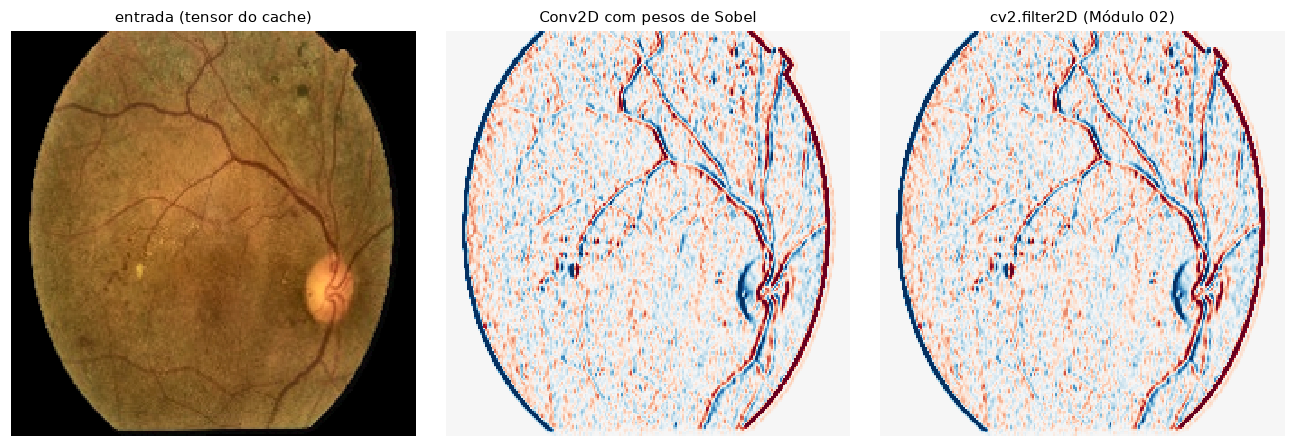

In [2]:
x = cache["aptos_0005"].astype(np.float32)                      # tensor 224×224×3 do cache (uint8 → float)
sobel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)

conv = keras.layers.Conv2D(1, 3, padding="same", use_bias=False)
conv.build((None, 224, 224, 3))
k = np.zeros((3, 3, 3, 1), np.float32); k[..., 1, 0] = sobel     # (altura, largura, canal de entrada, filtro)
conv.set_weights([k])

y_keras = conv(x[None]).numpy()[0, ..., 0]
y_cv2 = cv2.filter2D(x[..., 1], cv2.CV_32F, sobel, borderType=cv2.BORDER_CONSTANT)  # 'same' do Keras = borda com zeros
print("máx. |Keras − OpenCV| =", float(np.abs(y_keras - y_cv2).max()))

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(x.astype(np.uint8)); axs[0].set_title("entrada (tensor do cache)")
axs[1].imshow(y_keras, cmap="RdBu", vmin=-150, vmax=150); axs[1].set_title("Conv2D com pesos de Sobel")
axs[2].imshow(y_cv2, cmap="RdBu", vmin=-150, vmax=150); axs[2].set_title("cv2.filter2D (Módulo 02)")
for a in axs: a.axis("off")
fig.tight_layout(); plt.show()

A diferença é zero (a menos de arredondamento): **é a mesma operação**. O que muda numa CNN:

* os pesos começam **aleatórios** e são ajustados por **gradiente descendente** para reduzir o erro de classificação;
* cada camada tem **muitos** filtros (16, 32, 64…), e cada filtro olha para **todos os canais** da camada anterior;
* entre as convoluções vêm uma **não linearidade** (ReLU: `max(0, x)`) — sem ela, várias convoluções seguidas equivaleriam a uma só —
  e uma **redução** (*max pooling* 2×2), que diminui a resolução e aumenta a área da imagem "vista" por cada neurônio.

## 2. Anatomia de uma CNN pequena

`retina_iae.modelos.cnn_simples`: quatro blocos [Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2], média global (*global average pooling*) e
uma única saída sigmoide = P(RD referível). Entrada 128×128 para treinar rápido.

In [3]:
cnn = M.cnn_simples(128)
linhas = []
for c in cnn.layers[1:]:
    linhas.append({"camada": c.name, "tipo": type(c).__name__, "saída": str(c.output.shape[1:]), "parâmetros": c.count_params()})
pd.DataFrame(linhas).set_index("camada")

,tipo,saída,parâmetros
camada,,,
escala_0_1,Rescaling,"(128, 128, 3)",0
conv1,Conv2D,"(128, 128, 16)",432
bn1,BatchNormalization,"(128, 128, 16)",64
relu1,ReLU,"(128, 128, 16)",0
pool1,MaxPooling2D,"(64, 64, 16)",0
conv2,Conv2D,"(64, 64, 32)",4608
bn2,BatchNormalization,"(64, 64, 32)",128
relu2,ReLU,"(64, 64, 32)",0
pool2,MaxPooling2D,"(32, 32, 32)",0


In [4]:
# parâmetros de uma Conv2D = k·k·C_entrada·C_saída (+ viés). Conferindo a conv2 (3×3, 16 → 32, sem viés):
print("conv2:", 3 * 3 * 16 * 32, "=", cnn.get_layer("conv2").count_params())
print(f"total: {cnn.count_params():,} parâmetros ({cnn.count_params() * 4 / 1e6:.2f} MB em float32) · "
      f"{M.contar_macs(cnn) / 1e6:.0f} milhões de multiplicações-acumulações por imagem".replace(",", "."))

conv2: 4608 = 4608
total: 98.289 parâmetros (0.39 MB em float32) · 64 milhões de multiplicações-acumulações por imagem


**Campo receptivo:** quantos pixels da entrada influenciam um neurônio de cada camada. Cada conv 3×3 soma 2 × (passo atual); cada pooling
2×2 soma 1 × (passo) e dobra o passo:

In [5]:
rf, passo, linhas = 1, 1, []
for i in range(1, 5):
    rf += 2 * passo; linhas.append({"camada": f"conv{i}", "campo receptivo (px)": rf, "passo (px)": passo})
    rf += 1 * passo; passo *= 2; linhas.append({"camada": f"pool{i}", "campo receptivo (px)": rf, "passo (px)": passo})
pd.DataFrame(linhas).set_index("camada").T

camada,conv1,pool1,conv2,pool2,conv3,pool3,conv4,pool4
campo receptivo (px),3,4,8,10,18,22,38,46
passo (px),1,2,2,4,4,8,8,16


Depois de quatro blocos, cada neurônio "vê" um quadrado de ≈ 46 px numa imagem de 128 px (≈ 1/3 do diâmetro da retina) e o mapa final
tem 8×8 posições. Um microaneurisma ocupa 1–2 pixels nessa escala: a rede precisa **detectar padrões pequenos nas primeiras camadas** e
**combiná-los** nas últimas. Redes reais (notebook 03) têm 50–100 camadas e campo receptivo maior que a imagem inteira.

## 3. Dados da tarefa RD

APTOS 2019, RD referível (grau ≥ 2) × não referível (graus 0–1). Usamos as partições fixas de `data/particoes.csv`:

In [6]:
Xtr, ytr, ttr = D.conjunto("rd", "treino", cache)
Xva, yva, tva = D.conjunto("rd", "validacao", cache)
Xte, yte, tte = D.conjunto("rd", "teste", cache)
for nome, y_ in [("treino", ytr), ("validação", yva), ("teste", yte)]:
    print(f"{nome:10s} {len(y_):5d} imagens · {int(y_.sum()):4d} positivas ({100 * y_.mean():.1f} %)")
print(f"memória dos tensores de treino: {Xtr.nbytes / 1e6:.0f} MB (uint8)")

treino      2563 imagens · 1041 positivas (40.6 %)
validação    549 imagens ·  223 positivas (40.6 %)
teste        550 imagens ·  223 positivas (40.5 %)
memória dos tensores de treino: 386 MB (uint8)


### Uma linha de base sem aprendizado profundo

Antes de treinar uma CNN, vale saber quanto um método **simples** consegue: regressão logística sobre a imagem reduzida a 16×16 pixels
(768 números por imagem) — captura cor e brilho globais, mas nenhuma lesão pequena.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def miniatura(X, lado=16):
    return np.stack([cv2.resize(x, (lado, lado), interpolation=cv2.INTER_AREA).ravel() for x in X]).astype(np.float32)

base_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000)).fit(miniatura(Xtr), ytr)
auc_base = Me.auc(yva, base_lr.predict_proba(miniatura(Xva))[:, 1])
print(f"linha de base (logística em 16×16): AUC de validação = {auc_base:.3f}")

linha de base (logística em 16×16): AUC de validação = 0.927


A **AUC** (área sob a curva ROC) é a probabilidade de o modelo dar escore maior a um caso positivo sorteado do que a um negativo
sorteado: 0,5 = acaso, 1,0 = separação perfeita. Não depende de limiar — o limiar de triagem é escolhido só no notebook 06.

## 4. Treinando do zero: com e sem aumento de dados

Mesmo modelo, mesmos dados, 40 épocas no máximo (parada antecipada se a AUC de validação não melhorar em 6 épocas). A única diferença:
no segundo treino, cada imagem é **girada, espelhada, ampliada e tem brilho/cor alterados** aleatoriamente a cada época
(`treino.camada_aumento`). *(≈ 5–8 min em CPU.)*

In [8]:
historicos, modelos_ = {}, {}
for aumento in (False, True):
    nome = "com aumento" if aumento else "sem aumento"
    m = M.cnn_simples(128)
    t0 = time.time()
    historicos[nome] = T.treinar(m, (Xtr, ytr), (Xva, yva), epocas=40, lr=1e-3, aumento=aumento, paciencia=6, tamanho=128)
    modelos_[nome] = m
    h = historicos[nome]
    print(f"{nome:12s}: {len(h)} épocas em {time.time() - t0:.0f} s ({h.segundos.median():.1f} s/época) · "
          f"melhor AUC de validação = {h.val_auc.max():.3f} (época {int(h.epoca[h.val_auc.idxmax()])})")

sem aumento : 34 épocas em 265 s (7.7 s/época) · melhor AUC de validação = 0.984 (época 28)


com aumento : 27 épocas em 221 s (8.0 s/época) · melhor AUC de validação = 0.973 (época 21)


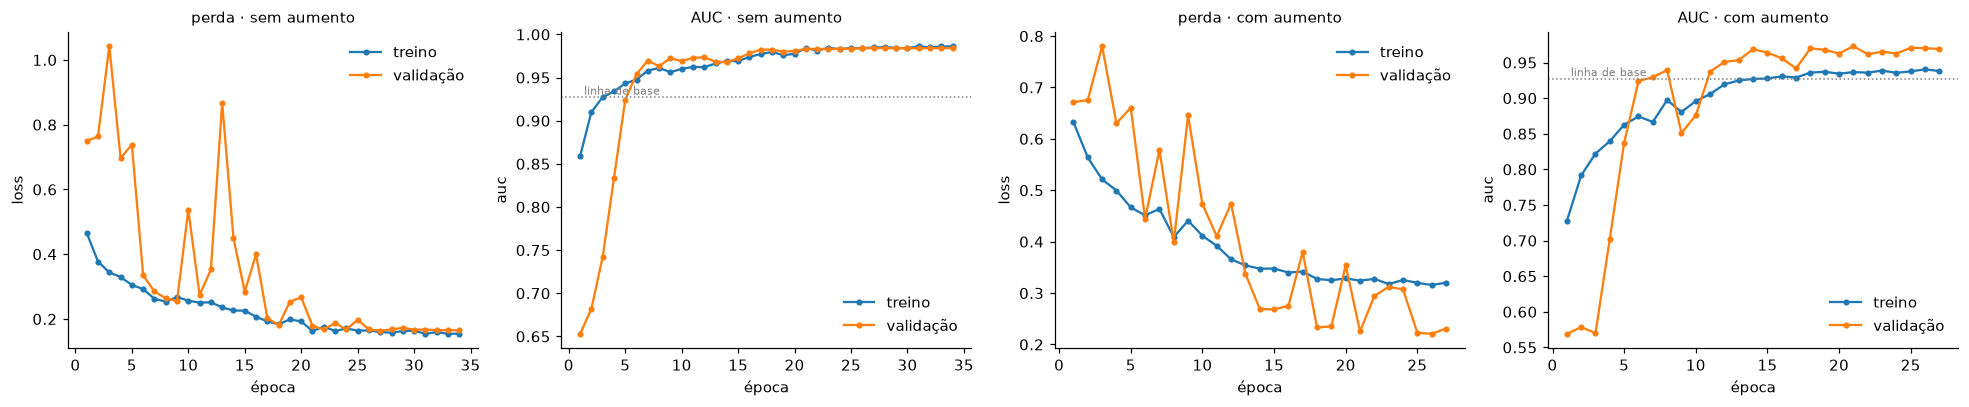

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for j, (nome, h) in enumerate(historicos.items()):
    V.historico(h, axs[2 * j], "loss", f"perda · {nome}")
    V.historico(h, axs[2 * j + 1], "auc", f"AUC · {nome}")
    axs[2 * j + 1].axhline(auc_base, color="gray", ls=":", lw=1); axs[2 * j + 1].text(1, auc_base, " linha de base", fontsize=7, color="gray", va="bottom")
fig.tight_layout(); V.salvar_figura(fig, "01_curvas_aumento"); plt.show()

Como ler as curvas:

* **Sem aumento**, treino e validação sobem juntos e se encontram em AUC ≈ 0,98: **não houve sobreajuste** visível. Com ≈ 100 mil parâmetros,
  2,5 mil imagens e BatchNorm, a rede tem pouca capacidade de "decorar". (Os picos da perda de validação nas primeiras épocas vêm das médias
  móveis do BatchNorm, ainda instáveis — não de sobreajuste.)
* **Com aumento**, a validação fica **acima** do treino: o treino é feito em imagens giradas, ampliadas e com cor alterada, mais difíceis que as
  imagens originais da validação. A tarefa fica mais difícil, a convergência mais lenta e a validação oscila mais.
* A parada antecipada guarda os pesos da **melhor época de validação**, não os da última.

Então o aumento de dados não serviu para nada? A resposta vem da tabela abaixo.

### Teste interno e uma câmera nova

Medimos as três abordagens no **teste** (APTOS, mesma fonte do treino) e no **DDR** (outra câmera, outro país — a validação externa do notebook 06,
antecipada aqui só para esta pergunta: *para que serve o aumento de dados?*).

In [10]:
Xdd, ydd, _ = D.conjunto("rd", "externo", cache, fonte="DDR")
linhas = []
avaliados = {f"CNN do zero ({nome})": (lambda X, m=m: T.prever(m, X)) for nome, m in modelos_.items()}
avaliados["logística em 16×16 (linha de base)"] = lambda X: base_lr.predict_proba(miniatura(X))[:, 1]
for nome, prever_ in avaliados.items():
    a, lo, hi = Me.bootstrap(yte, prever_(Xte), Me.auc, n=500)
    b, blo, bhi = Me.bootstrap(ydd, prever_(Xdd), Me.auc, n=500)
    linhas.append({"modelo": nome, "AUC teste (APTOS)": round(a, 3), "IC 95 % teste": f"{lo:.3f}–{hi:.3f}",
                   "AUC externo (DDR)": round(b, 3), "IC 95 % DDR": f"{blo:.3f}–{bhi:.3f}"})
resultado_01 = pd.DataFrame(linhas).set_index("modelo"); resultado_01

,AUC teste (APTOS),IC 95 % teste,AUC externo (DDR),IC 95 % DDR
modelo,,,,
CNN do zero (sem aumento),0.985,0.977–0.991,0.796,0.752–0.837
CNN do zero (com aumento),0.966,0.951–0.978,0.773,0.734–0.810
logística em 16×16 (linha de base),0.937,0.918–0.954,0.533,0.487–0.583


O intervalo de confiança (IC 95 %, por *bootstrap*: reamostrando as imagens 500 vezes) mostra a incerteza que vem do tamanho
do conjunto. Diferenças menores que a largura do IC **não** permitem dizer que um modelo é melhor que outro. Três lições desta tabela:

1. **O aumento de dados não ajudou aqui** — nem no teste, nem no DDR (os ICs se sobrepõem). Com este modelo pequeno e este orçamento de épocas,
   não havia sobreajuste para combater. Técnicas não são leis: **meça**. (Nas redes de milhões de parâmetros do notebook 03, o aumento fica ligado.)
2. **A linha de base desaba numa câmera nova:** de ≈ 0,94 no APTOS para ≈ 0,53 no DDR — praticamente o acaso. Uma miniatura 16×16 só carrega
   cor e brilho globais; no APTOS isso "funciona" por correlação com a doença (retinas com muitos exsudatos ficam mais amarelas), no DDR a
   correlação some. Esse é o perigo de um **atalho**: ótimo no teste, inútil no mundo.
3. **A CNN também cai** (≈ 0,98 → ≈ 0,80), mas continua bem acima do acaso: aprendeu algo que **transfere** — lesões — junto com algo que não
   transfere. Reduzir essa distância é o tema dos notebooks 02 (transfer learning) e 06 (validação externa).

## 5. Dentro da rede: o que ela aprendeu?

### Filtros da primeira camada
São 16 filtros 3×3×3 — pequenos demais para "parecer" algo, mas dá para ver detectores de cor (vermelho × verde) e de bordas:

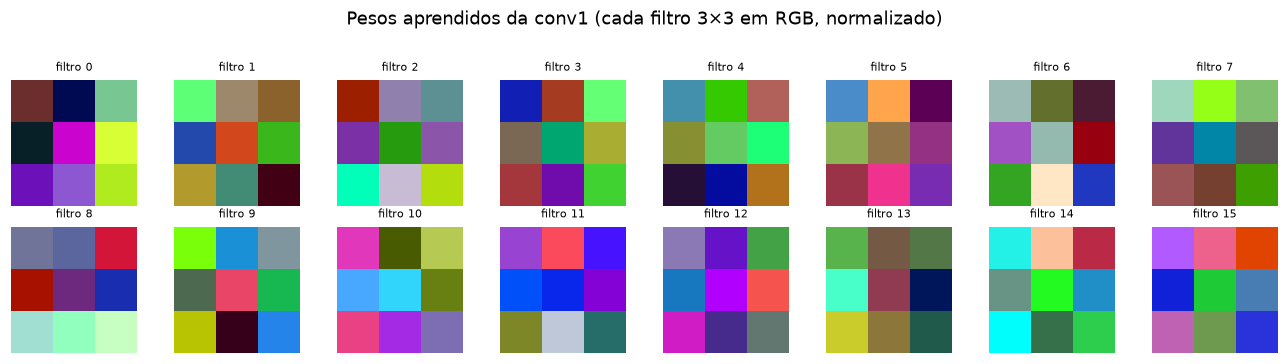

In [11]:
m = modelos_["com aumento"]
w = m.get_layer("conv1").get_weights()[0]                       # (3, 3, 3, 16)
fig, axs = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axs.ravel()):
    f = w[..., i]; f = (f - f.min()) / (np.ptp(f) + 1e-8)
    ax.imshow(f, interpolation="nearest"); ax.set_title(f"filtro {i}", fontsize=7); ax.axis("off")
fig.suptitle("Pesos aprendidos da conv1 (cada filtro 3×3 em RGB, normalizado)", y=1.02); fig.tight_layout(); plt.show()

### Mapas de ativação
O que cada bloco "acende" numa imagem com RD referível. Mostramos os 4 canais mais ativos de cada bloco:

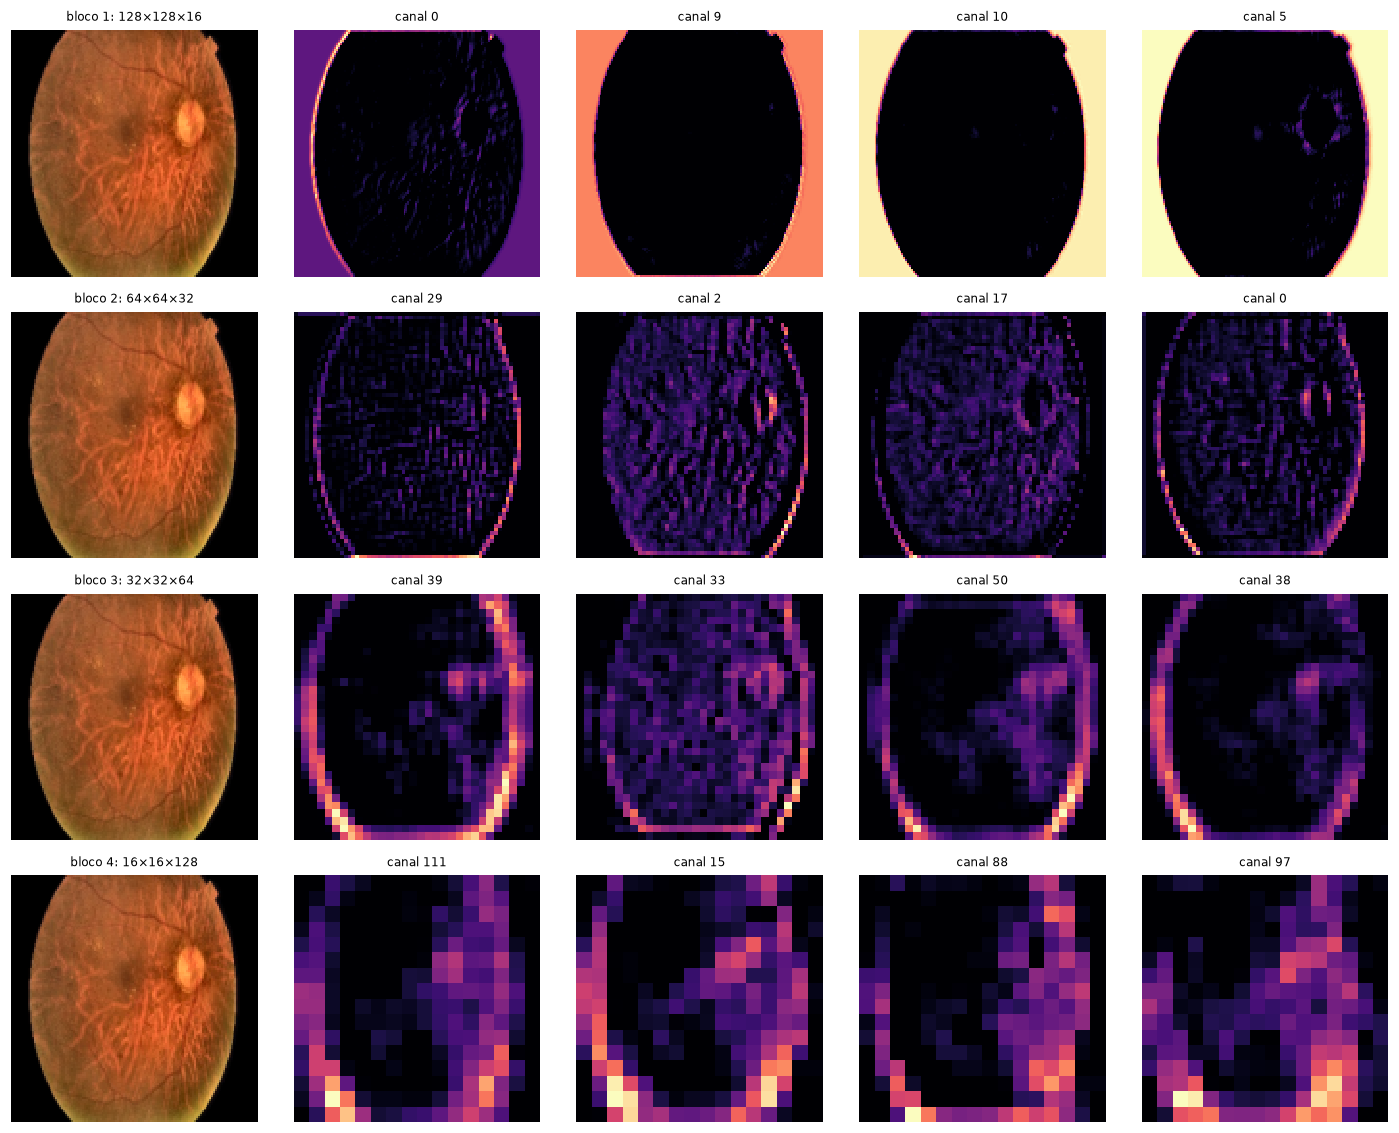

In [12]:
idx_pos = int(np.where((yte == 1) & (T.prever(m, Xte) > 0.8))[0][0])
img = cv2.resize(Xte[idx_pos], (128, 128), interpolation=cv2.INTER_AREA)
sonda = keras.Model(m.inputs, [m.get_layer(f"relu{i}").output for i in range(1, 5)])
mapas = sonda(img[None].astype(np.float32))
fig, axs = plt.subplots(4, 5, figsize=(13, 10.4))
for i, mp in enumerate(mapas):
    mp = mp.numpy()[0]
    axs[i, 0].imshow(img); axs[i, 0].set_title(f"bloco {i + 1}: {mp.shape[0]}×{mp.shape[1]}×{mp.shape[2]}", fontsize=8)
    for j, c in enumerate(np.argsort(mp.mean(axis=(0, 1)))[::-1][:4]):
        axs[i, j + 1].imshow(mp[..., c], cmap="magma"); axs[i, j + 1].set_title(f"canal {c}", fontsize=8)
for a in axs.ravel(): a.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "01_mapas_ativacao"); plt.show()

Nos primeiros blocos os mapas ainda lembram a imagem (bordas, vasos, regiões claras); nos últimos, a resolução cai (8×8) e cada canal
responde a combinações mais abstratas. A camada final só tira a **média** de cada canal e pondera: "quanto deste padrão existe na imagem".

### Grad-CAM: onde está a evidência?
O **Grad-CAM** pondera os canais do último mapa pelo gradiente da saída em relação a eles e mostra *onde* a combinação favorece "RD".
É uma pista, não uma prova — e numa rede tão pequena, com mapa 8×8 (ou 16×16 antes do último pooling), a localização é grosseira.

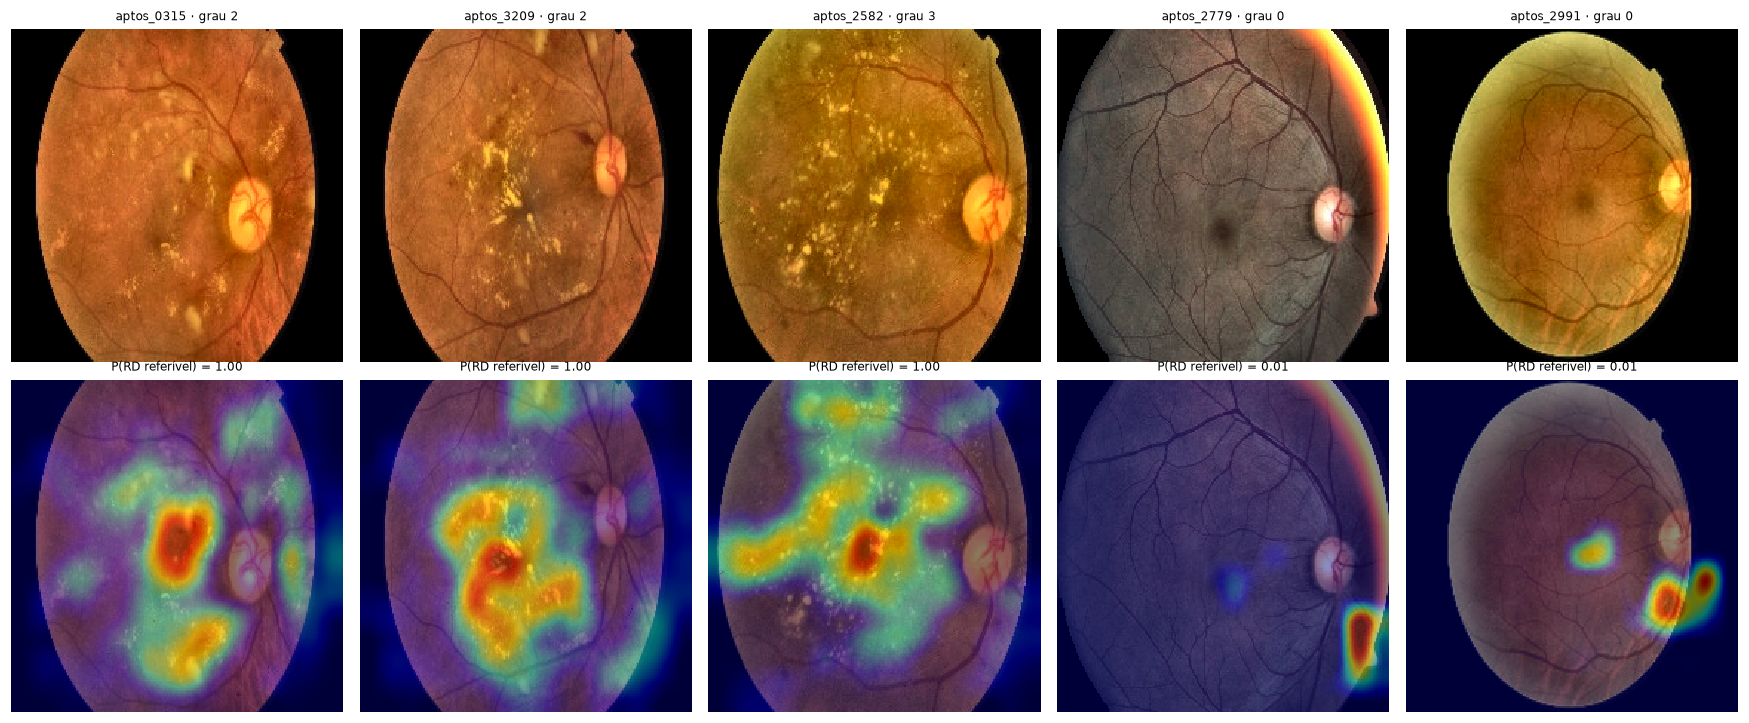

In [13]:
from retina_iae.explicacao import gradcam
pt = T.prever(m, Xte)
escolhidos = list(np.where(yte == 1)[0][np.argsort(-pt[yte == 1])[:3]]) + list(np.where(yte == 0)[0][np.argsort(pt[yte == 0])[:2]])
fig, axs = plt.subplots(2, len(escolhidos), figsize=(3.2 * len(escolhidos), 6.6))
for j, i in enumerate(escolhidos):
    im128 = cv2.resize(Xte[i], (128, 128), interpolation=cv2.INTER_AREA)
    cam = gradcam(m, im128, camada="relu4")
    axs[0, j].imshow(Xte[i]); axs[0, j].set_title(f"{tte.id[i]} · grau {D.carregar_manifesto().set_index('id').loc[tte.id[i], 'grau']}", fontsize=8)
    axs[1, j].imshow(V.sobrepor_mapa(Xte[i], cam)); axs[1, j].set_title(f"P(RD referível) = {pt[i]:.2f}", fontsize=8)
for a in axs.ravel(): a.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "01_gradcam"); plt.show()

Nos casos positivos, o mapa costuma cair sobre **exsudatos e hemorragias** (manchas amarelas e vermelhas); nos negativos, é difuso.
Quando cair na borda da retina ou no disco óptico, desconfie: pode ser um atalho (*shortcut*) — o tema do notebook 06.

## Resumo

| Conceito | O que vimos |
|---|---|
| convolução | a mesma operação do Módulo 02; numa CNN os pesos são **aprendidos** |
| profundidade | blocos conv → ReLU → pooling aumentam o campo receptivo e a abstração |
| sobreajuste | perda de treino cai e a de validação sobe; aqui **não** apareceu, e o aumento de dados não melhorou o resultado — medir, não presumir |
| avaliação | AUC com IC; sempre contra uma **linha de base** simples e, se possível, numa **fonte externa** |
| atalhos | a linha de base "acertava" o APTOS pela cor e caiu ao acaso no DDR |

Uma CNN do zero, com 2,5 mil imagens, supera a linha de base e generaliza melhor que ela — mas perde ≈ 0,18 de AUC numa câmera nova.
Redes pré-treinadas em milhões de imagens são o tema do notebook 02.

## Exercícios propostos

1. **Largura e profundidade.** Treine `cnn_simples(128, filtros=(32, 64, 128, 256))` e `cnn_simples(128, filtros=(16, 32))`.
   Compare parâmetros, tempo por época e AUC de validação. Mais parâmetros sempre ajuda?
2. **Resolução.** Treine a mesma CNN com entrada 64 e 224. Use o campo receptivo da seção 2 para explicar o que muda.
3. **Aumento de dados, peça por peça.** Treine só com o aumento **fotométrico** (cor/brilho), só com o **geométrico** e com os dois, por
   60 épocas. Algum melhora a AUC no **DDR**? Por que a rotação de ±180° faz sentido em retinografia e não faria em fotos de rua?
4. **Pesos de classe.** Treine com `balancear=False`. O que acontece com a AUC? E com a acurácia num limiar de 0,5? Por quê?
5. **Linha de base melhor.** Acrescente à logística a fração de pixels "amarelos" (exsudatos) dentro do FOV, medida no espaço HSV
   (notebook 02 do Módulo 02). Quanto a AUC sobe?